
# PyTorch e CIFAR-10

Librerie necessarie:
- `pytorch` 
    - https://pytorch.org/
    - https://docs.pytorch.org/docs/stable/index.html
- `numpy`
- `matplotlib`

In [40]:
import torch
import torchvision
import numpy as np

import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

#### Caricamento del dataset

Passaggi:
- definizione delle trasformazioni da applicare alle immagini in input
- selezione del dataset CIFAR-10
- selezione del batch size
- creazione dei generatori python (DataLoader) per l'uso del dataset
- definizione delle etichette di classe

In [41]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # media, varianza
]) # trasformazioni da applicare al dataset

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

batch_size = 8 ## SI PUO' MODIFICARE

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

#### Configurazione degli iperparametri

In [42]:
# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
num_epochs = 20
learning_rate = 0.05

#### Definizione della rete neurale

Creare un modulo pytorch (classe derivata da `nn.Module`) che definisce l'architettura della rete.  
Devono essere presenti due strati convoluzionali con pooling, concatenati infine a un MLP con 10 neuroni di output.

In [43]:
# Define the CNN
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

model = SimpleCNN().to(device)

#### Scelta della funzione Loss e dell'ottimizzatore

- Cross-entropy loss
- SGD optimizer

In [44]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

Implementare l'algoritmo di training della rete neurale sopra definita, ricordando che:
- per un certo numero di epoche, si itera su tutto il dataset
    - inoltre, i comandi `inputs.to(device), labels.to(device)` assicurano di utilizzare la GPU
- l'ottimizzatore va resettato a ogni iterazione, con `optimizer.zero_grad()`
- per ogni iterazione, si procede con il passo forward
- per ogni iterazione, si calcola la loss relativa a quell'output della rete
    - con `loss = criterion(outputs, labels)`
- per ogni iterazione, si propaga all'indietro la loss
- per ogni iterazione, si esegue uno step dell'ottimizzatore

In [45]:
# recuperare ultimi 5 minuti di lezione

for epoch in range(num_epochs):
    running_loss = 0.0

    for i, (inputs, labels) in enumerate(train_loader, 0):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        if i % 1000 == 999:
            print(f'[Epoch {epoch + 1}, Batch {i + 1}] Loss: {running_loss / 1000:.3f}')
            running_loss = 0.0


[Epoch 1, Batch 1000] Loss: 2.077
[Epoch 1, Batch 2000] Loss: 1.763
[Epoch 1, Batch 3000] Loss: 1.642
[Epoch 1, Batch 4000] Loss: 1.551
[Epoch 1, Batch 5000] Loss: 1.510
[Epoch 1, Batch 6000] Loss: 1.485
[Epoch 2, Batch 1000] Loss: 1.415
[Epoch 2, Batch 2000] Loss: 1.394
[Epoch 2, Batch 3000] Loss: 1.381
[Epoch 2, Batch 4000] Loss: 1.354
[Epoch 2, Batch 5000] Loss: 1.326
[Epoch 2, Batch 6000] Loss: 1.347
[Epoch 3, Batch 1000] Loss: 1.261
[Epoch 3, Batch 2000] Loss: 1.286
[Epoch 3, Batch 3000] Loss: 1.307
[Epoch 3, Batch 4000] Loss: 1.287
[Epoch 3, Batch 5000] Loss: 1.273
[Epoch 3, Batch 6000] Loss: 1.267
[Epoch 4, Batch 1000] Loss: 1.198
[Epoch 4, Batch 2000] Loss: 1.243
[Epoch 4, Batch 3000] Loss: 1.209
[Epoch 4, Batch 4000] Loss: 1.233
[Epoch 4, Batch 5000] Loss: 1.246
[Epoch 4, Batch 6000] Loss: 1.247
[Epoch 5, Batch 1000] Loss: 1.170
[Epoch 5, Batch 2000] Loss: 1.205
[Epoch 5, Batch 3000] Loss: 1.206
[Epoch 5, Batch 4000] Loss: 1.216
[Epoch 5, Batch 5000] Loss: 1.186
[Epoch 5, Batc

#### Inferenza

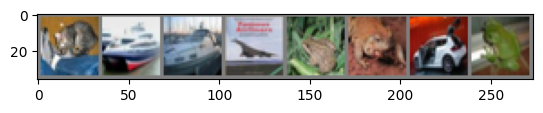

GroundTruth:  cat ship ship plane frog frog car frog
Predicted:  cat ship truck plane deer frog truck frog


In [46]:
# Visualization
def imshow(img):
    img = img / 2 + 0.5  # Unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

dataiter = iter(test_loader)
images, labels = next(dataiter)

# Show images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]}' for j in range(batch_size)))

# Predict
images = images.to(device)
outputs = model(images)
_, predicted = torch.max(outputs, 1)

print('Predicted: ', ' '.join(f'{classes[predicted[j]]}' for j in range(batch_size)))

Altri esempi di addestramento reti con Pytorch:
https://docs.pytorch.org/examples/